# Global Solution — Aprendizado Profundo com Redes Neurais Convolucionais

**Integrantes:** Leonardo Kenji Kubo Barboza — RM 567518; Lucas Gabriel Alvarenga e Meireles — RM 567305.

**Fonte:** [SSP-SP — Portal de Estatísticas](https://www.ssp.sp.gov.br/estatistica/consultas)  
**Arquivo:** `CelularesSubtraidos_2026.xlsx`, aba `CELULAR_2026`.  
**Problema:** classificar o tipo de uma ocorrência que já aconteceu (roubo ou furto).

## 1. Bibliotecas

In [ ]:
# Executar esta instalação apenas se alguma biblioteca estiver ausente.
# !pip install -q openpyxl tensorflow scikit-learn joblib

# Manipulação e análise de dados.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Divisão, codificação e escalonamento.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# Construção das redes neurais.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Salvar o pré-processador e as informações usadas pela aplicação.
import joblib
import json
import os

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 2. Carregamento dos dados

In [ ]:
# No Google Colab, selecione o arquivo Excel que foi baixado da SSP-SP.
from google.colab import files
arquivos = files.upload()

ARQUIVO = 'CelularesSubtraidos_2026.xlsx'
ABA = 'CELULAR_2026'

# A planilha contém outras abas (metodologia e dicionário de dados).
# Lemos apenas a aba das ocorrências.
df = pd.read_excel(ARQUIVO, sheet_name=ABA, engine='openpyxl')
print('Formato (linhas, colunas):', df.shape)
display(df.head())

Saving CelularesSubtraidos_2026.xlsx to CelularesSubtraidos_2026.xlsx
Formato (linhas, colunas): (256076, 55)


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,...,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,COD IBGE
0,10101,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2025,TB7197,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,20230,DECAP,DEL.SEC.5º LESTE,30º D.P. TATUAPE,S.PAULO,2026,AA0506,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,NaN,NaN,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA1535,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA1574,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA2028,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308


## 3. Análise exploratória dos dados

### 3.1. Análise inicial do conjunto de dados

In [ ]:
print('Formato:', df.shape)
display(df.dtypes.to_frame('dtype'))
display(df.head())
print('Colunas disponíveis:')
print(df.columns.tolist())

Formato: (256076, 55)


,dtype
ID_DELEGACIA,int64
NOME_DEPARTAMENTO,object
NOME_SECCIONAL,object
NOME_DELEGACIA,object
NOME_MUNICIPIO,object
ANO_BO,int64
NUM_BO,object
VERSAO,int64
NOME_DEPARTAMENTO_CIRC,object
NOME_SECCIONAL_CIRC,object


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,...,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,COD IBGE
0,10101,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2025,TB7197,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,20230,DECAP,DEL.SEC.5º LESTE,30º D.P. TATUAPE,S.PAULO,2026,AA0506,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,NaN,NaN,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA1535,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA1574,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2026,AA2028,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2026,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308


Colunas disponíveis:
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'COD IBGE']


### 3.2. Tipos de variáveis

In [ ]:
numericas = df.select_dtypes(include=np.number).columns.tolist()
categoricas = df.select_dtypes(exclude=np.number).columns.tolist()
print('Numéricas:', numericas)
print('\nNão numéricas:', categoricas)

Numéricas: ['ID_DELEGACIA', 'ANO_BO', 'VERSAO', 'CEP', 'LOGRADOURO_VERSAO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'QUANTIDADE_OBJETO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'COD IBGE']

Não numéricas: ['NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'NUM_BO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'LOGRADOURO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'CMD', 'BTL', 'CIA']


### 3.3. Dados ausentes

In [ ]:
# O arquivo também usa a string 'NULL' para sinalizar campos não preenchidos.
df = df.replace(['NULL', 'null', ''], np.nan)

faltantes = pd.DataFrame({
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(2)
})
display(faltantes[faltantes['nulos'] > 0].sort_values('nulos', ascending=False))

,nulos,% nulos
TIPO_INTOLERANCIA,256054,99.99
DESDOBRAMENTO,249132,97.29
CIRCUNSTANCIA,213113,83.22
DESCR_UNIDADE,169535,66.20
DESCR_PERIODO,148874,58.14
DESCR_CONDUTA,115113,44.95
HORA_OCORRENCIA,107202,41.86
CEP,21090,8.24
LONGITUDE,17687,6.91
LATITUDE,17687,6.91


### 3.4. Valores indefinidos

In [ ]:
for coluna in df.select_dtypes(include='object').columns:
    quantidade = df[coluna].astype(str).str.strip().eq('Undefined').sum()
    if quantidade > 0:
        print(f'{coluna}: {quantidade} valores Undefined')

### 3.5. Duplicatas e boletins com múltiplos itens

In [ ]:
print('Linhas idênticas:', df.duplicated().sum())

# Um mesmo BO pode descrever vários objetos/celulares.
# Os identificadores do BO são examinados antes de escolher uma linha por ocorrência.
chave_bo = ['ID_DELEGACIA', 'ANO_BO', 'NUM_BO']
print('Linhas com chave de BO repetida:', df.duplicated(subset=chave_bo).sum())
display(df[chave_bo].head())

Linhas idênticas: 319
Linhas com chave de BO repetida: 45314


,ID_DELEGACIA,ANO_BO,NUM_BO
0,10101,2025,TB7197
1,20230,2026,AA0506
2,900020,2026,AA1535
3,900020,2026,AA1574
4,900020,2026,AA2028


### 3.6. Estatísticas descritivas das colunas numéricas

In [ ]:
display(df.describe(include='number').T.round(2))

,count,mean,std,min,25%,50%,75%,max
ID_DELEGACIA,256076.0,6.210133e+05,401914.01,1.000400e+04,7.040300e+04,9.000200e+05,9.000200e+05,9.909000e+05
ANO_BO,256076.0,2.026000e+03,0.04,2.022000e+03,2.026000e+03,2.026000e+03,2.026000e+03,2.026000e+03
VERSAO,256076.0,1.250000e+00,0.60,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+01
CEP,234986.0,6.696542e+06,5093478.47,0.000000e+00,3.178200e+06,5.433000e+06,9.080500e+06,1.000000e+08
LOGRADOURO_VERSAO,256076.0,1.040000e+00,0.24,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,6.000000e+00
NUMERO_LOGRADOURO,238697.0,6.911457e+05,55598954.22,0.000000e+00,6.500000e+01,2.730000e+02,8.970000e+02,1.000000e+10
LATITUDE,238389.0,-4.616500e+02,29012.79,-2.363499e+06,-2.360000e+01,-2.354000e+01,-2.347000e+01,0.000000e+00
LONGITUDE,238389.0,-9.124500e+02,57261.00,-4.664112e+06,-4.674000e+01,-4.665000e+01,-4.652000e+01,0.000000e+00
CONT_OBJETO,256076.0,1.012321e+09,571596.36,1.001732e+09,1.011839e+09,1.012311e+09,1.012824e+09,1.013389e+09
QUANTIDADE_OBJETO,256076.0,1.100000e+00,5.12,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.453000e+03


### 3.7. Distribuição inicial das naturezas de ocorrência

In [ ]:
print('Municípios mais frequentes:')
display(df['CIDADE'].value_counts(dropna=False).head(10))
print('Naturezas mais frequentes:')
display(df['RUBRICA'].value_counts(dropna=False).head(15))

Municípios mais frequentes:


,count
CIDADE,
S.PAULO,150990
GUARULHOS,7090
CAMPINAS,5577
S.ANDRE,4967
OSASCO,4823
S.BERNARDO DO CAMPO,3834
PRAIA GRANDE,2801
SOROCABA,2408
RIBEIRAO PRETO,2334


Naturezas mais frequentes:


,count
RUBRICA,
Furto (art. 155),117027
Roubo (art. 157),82559
Perda/Extravio,38104
Localização/Apreensão e Entrega de veículo,3218
Outros não criminal,2485
Estelionato (art. 171),1843
Lesão corporal (art. 129),1289
Localização/Apreensão de veículo,1053
Violência Doméstica,952


### 3.8. Verificação de data leakage

In [ ]:
# A variável-alvo será obtida de RUBRICA (roubo/furto).
# Por isso, RUBRICA, DESC_LEI, DESCR_CONDUTA, DESDOBRAMENTO etc.
# não entram na lista de atributos de entrada.
# Também não usaremos dados pessoais, identificação de BO ou dados da delegacia.
atributos_candidatos = ['BAIRRO', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCR_TIPOLOCAL']
print('Atributos candidatos:', atributos_candidatos)
print('Rótulo original: RUBRICA — NÃO entra em X')

Atributos candidatos: ['BAIRRO', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCR_TIPOLOCAL']
Rótulo original: RUBRICA — NÃO entra em X


## 4. Tratamento e limpeza dos dados

### 4.1. Filtrar município da ocorrência e definir o alvo

In [ ]:
# CIDADE representa o local do fato; NOME_MUNICIPIO é o local da delegacia.
df_limpo = df[df['CIDADE'].astype(str).str.strip().str.upper().eq('S.PAULO')].copy()

# Classes explícitas: sem incluir outros delitos ou eventos ambíguos.
mapa_classes = {'Furto (art. 155)': 0, 'Roubo (art. 157)': 1}
df_limpo['RUBRICA'] = df_limpo['RUBRICA'].astype(str).str.strip()
df_limpo = df_limpo[df_limpo['RUBRICA'].isin(mapa_classes)].copy()
df_limpo['classe'] = df_limpo['RUBRICA'].map(mapa_classes).astype(int)

print('Registros da capital classificados como roubo/furto:', len(df_limpo))
print(df_limpo['classe'].value_counts().rename(index={0:'Furto', 1:'Roubo'}))

Registros da capital classificados como roubo/furto: 126567
classe
Furto    77003
Roubo    49564
Name: count, dtype: int64


### 4.2. Remover duplicatas de boletins

In [ ]:
# Elimina primeiro as linhas 100% iguais.
df_limpo = df_limpo.drop_duplicates()

# A identificação do BO não inclui a versão. Assim, versões diferentes
# do mesmo boletim não poderão cair em treino e teste ao mesmo tempo.
chave_bo = ['ID_DELEGACIA', 'ANO_BO', 'NUM_BO']

# Se o mesmo BO possui rótulos distintos, exclui a chave ambígua.
classes_por_bo = df_limpo.groupby(chave_bo, dropna=False)['classe'].transform('nunique')
ambiguos = (classes_por_bo > 1).sum()
df_limpo = df_limpo[classes_por_bo == 1].copy()

# Em boletins com várias versões ou objetos, mantém a última versão.
df_limpo['VERSAO'] = pd.to_numeric(df_limpo['VERSAO'], errors='coerce')
df_limpo = df_limpo.sort_values('VERSAO', ascending=False)
df_limpo = df_limpo.drop_duplicates(subset=chave_bo).copy()
print('Linhas retiradas por ambiguidade de classe:', ambiguos)
print('Registros únicos após limpeza:', len(df_limpo))

Linhas retiradas por ambiguidade de classe: 111
Registros únicos após limpeza: 112165


### 4.3. Construção das variáveis de entrada

In [ ]:
# Dia da semana é derivado da data do FATO, e não da data de registro.
df_limpo['DATA_OCORRENCIA_BO'] = pd.to_datetime(df_limpo['DATA_OCORRENCIA_BO'], errors='coerce')
df_limpo['dia_semana'] = df_limpo['DATA_OCORRENCIA_BO'].dt.dayofweek

# HORA_OCORRENCIA pode vir como time, texto ou valor ausente.
# Criamos a hora numérica sem assumir horário para dados faltantes.
def extrair_hora(valor):
    if pd.isna(valor):
        return np.nan
    try:
        return int(str(valor).split(':')[0])
    except (ValueError, TypeError):
        return np.nan

df_limpo['hora'] = df_limpo['HORA_OCORRENCIA'].apply(extrair_hora)
df_limpo.loc[~df_limpo['hora'].between(0, 23), 'hora'] = np.nan

# Valores categóricos ausentes terão categoria própria.
df_limpo['BAIRRO'] = df_limpo['BAIRRO'].fillna('Desconhecido').astype(str).str.strip().str.upper()
df_limpo['DESCR_TIPOLOCAL'] = df_limpo['DESCR_TIPOLOCAL'].fillna('Desconhecido').astype(str).str.strip()

# A hora não informada recebe uma categoria própria; facilita o formulário web.
def periodo_do_dia(hora):
    if pd.isna(hora): return 'Desconhecido'
    if hora < 6: return 'Madrugada'
    if hora < 12: return 'Manhã'
    if hora < 18: return 'Tarde'
    return 'Noite'

df_limpo['periodo'] = df_limpo['hora'].apply(periodo_do_dia)
df_limpo['dia_semana'] = df_limpo['dia_semana'].map({
    0:'Segunda', 1:'Terça', 2:'Quarta', 3:'Quinta',
    4:'Sexta', 5:'Sábado', 6:'Domingo'
}).fillna('Desconhecido')

# Os atributos do formulário serão exatamente os utilizados na MLP.
atributos = ['BAIRRO', 'dia_semana', 'periodo', 'DESCR_TIPOLOCAL']
alvo = 'classe'
df_limpo = df_limpo[atributos + [alvo]].copy()

display(df_limpo.head())

,BAIRRO,dia_semana,periodo,DESCR_TIPOLOCAL,classe
237202,SANTANA,Segunda,Desconhecido,Via Pública,0
231930,BOSQUE DA SAÚDE,Sexta,Manhã,Via Pública,1
126892,VILA MARIA,Sábado,Noite,Residência,1
7948,JARDIM COLOMBO,Segunda,Tarde,Via Pública,1
68742,CIDADE ADEMAR,Quinta,Tarde,Comércio e Serviços,1


### 4.4. Selecionar amostra para o projeto

Amostra final: (20000, 5)


,proportion
classe,
Furto,65.01
Roubo,34.99


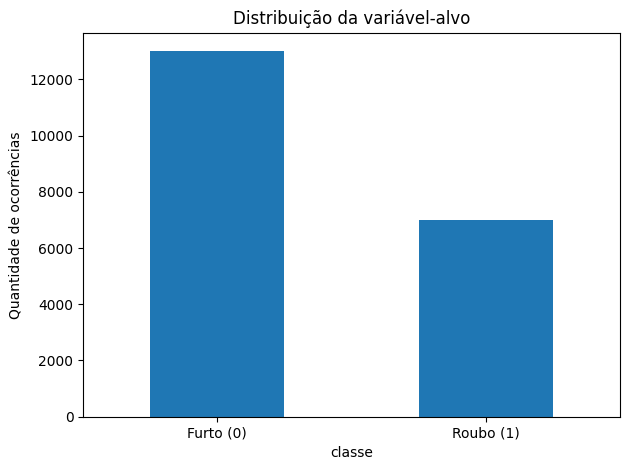

In [ ]:
# Uma amostra reprodutível de até 20 mil linhas mantém a proporção original.
N_AMOSTRA = min(20000, len(df_limpo))
if len(df_limpo) > N_AMOSTRA:
    amostra, _ = train_test_split(
        df_limpo, train_size=N_AMOSTRA, stratify=df_limpo[alvo], random_state=SEED
    )
else:
    amostra = df_limpo.copy()
amostra = amostra.reset_index(drop=True)
print('Amostra final:', amostra.shape)
display(amostra[alvo].value_counts(normalize=True).mul(100).round(2).rename(index={0:'Furto',1:'Roubo'}))

amostra[alvo].value_counts().sort_index().plot(kind='bar')
plt.xticks([0, 1], ['Furto (0)', 'Roubo (1)'], rotation=0)
plt.ylabel('Quantidade de ocorrências')
plt.title('Distribuição da variável-alvo')
plt.tight_layout()
plt.show()

## 5. Divisão dos dados

### 5.1. Treinamento (70%), validação (15%) e teste (15%)

In [ ]:
train, temp = train_test_split(
    amostra, test_size=0.30, stratify=amostra[alvo], random_state=SEED
)
val, test = train_test_split(
    temp, test_size=0.50, stratify=temp[alvo], random_state=SEED
)
for nome, parte in [('Treino', train), ('Validação', val), ('Teste', test)]:
    print(f'{nome}: {len(parte)} registros | % roubo: {parte[alvo].mean():.2%}')

Treino: 14000 registros | % roubo: 34.99%
Validação: 3000 registros | % roubo: 35.00%
Teste: 3000 registros | % roubo: 34.97%


### 5.2. Separação das entradas (X) e saída (y)

In [ ]:
X_train, y_train = train.drop(columns=[alvo]).copy(), train[alvo].copy()
X_val, y_val = val.drop(columns=[alvo]).copy(), val[alvo].copy()
X_test, y_test = test.drop(columns=[alvo]).copy(), test[alvo].copy()
print('Treino:', X_train.shape, y_train.shape)
print('Validação:', X_val.shape, y_val.shape)
print('Teste:', X_test.shape, y_test.shape)

Treino: (14000, 4) (14000,)
Validação: (3000, 4) (3000,)
Teste: (3000, 4) (3000,)


## 6. Pré-processamento

### 6.1. Agrupamento de bairros e tipos de local pouco frequentes

In [ ]:
# Define as categorias frequentes usando SOMENTE os dados de treino.
# Guarda as listas para aplicar as mesmas regras à aplicação web.
def agrupar_raras(X_tr, X_va, X_te, coluna, top_n, protegidos=('Desconhecido',)):
    frequentes = X_tr[coluna].value_counts().head(top_n).index.tolist()
    manter = set(frequentes) | set(protegidos)
    for X in (X_tr, X_va, X_te):
        X[coluna] = X[coluna].where(X[coluna].isin(manter), 'Outros')
    return sorted(manter)

bairros_mantidos = agrupar_raras(X_train, X_val, X_test, 'BAIRRO', 30)
locais_mantidos = agrupar_raras(X_train, X_val, X_test, 'DESCR_TIPOLOCAL', 15)
print('Bairros mantidos:', len(bairros_mantidos))
print('Tipos de local mantidos:', len(locais_mantidos))

Bairros mantidos: 31
Tipos de local mantidos: 16


### 6.2. Codificação dos atributos

In [ ]:
# Todas as entradas são categóricas, portanto OneHotEncoder é suficiente.
# O escalonamento de StandardScaler não é necessário neste recorte: não há
# atributos numéricos contínuos entre as entradas.
categoricas = atributos
preprocessador = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)
])

# Ajusta apenas no conjunto de treino para evitar vazamento de informações.
X_train_p = preprocessador.fit_transform(X_train).astype('float32')
X_val_p = preprocessador.transform(X_val).astype('float32')
X_test_p = preprocessador.transform(X_test).astype('float32')

print('Treino:', X_train_p.shape)
print('Validação:', X_val_p.shape)
print('Teste:', X_test_p.shape)

Treino: (14000, 58)
Validação: (3000, 58)
Teste: (3000, 58)


## 7. Metodologia experimental

In [ ]:
# Parâmetros compartilhados para comparar as arquiteturas de modo justo.
EPOCAS = 40
BATCH = 128
LR = 0.001
LIMIAR = 0.5

y_train_a = y_train.to_numpy(dtype='float32')
y_val_a = y_val.to_numpy(dtype='float32')

def construir_mlp(n_entrada, camadas, ativacao='relu', dropout=0.0, lr=LR):
    keras.utils.set_random_seed(SEED)
    modelo = keras.Sequential()
    modelo.add(keras.Input(shape=(n_entrada,)))

    for n_neuronios in camadas:
        modelo.add(layers.Dense(n_neuronios, activation=ativacao))
        if dropout > 0:
            modelo.add(layers.Dropout(dropout))

    # Uma saída sigmoid estima P(roubo) para uma ocorrência informada.
    modelo.add(layers.Dense(1, activation='sigmoid'))
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return modelo

### 7.1. Experimentos com três arquiteturas

In [ ]:
experimentos = {
    'E1': {'camadas': [32], 'ativacao': 'relu', 'dropout': 0.0},
    'E2': {'camadas': [64, 32], 'ativacao': 'relu', 'dropout': 0.0},
    'E3': {'camadas': [128, 64, 32], 'ativacao': 'relu', 'dropout': 0.2},
}
print(experimentos)

{'E1': {'camadas': [32], 'ativacao': 'relu', 'dropout': 0.0}, 'E2': {'camadas': [64, 32], 'ativacao': 'relu', 'dropout': 0.0}, 'E3': {'camadas': [128, 64, 32], 'ativacao': 'relu', 'dropout': 0.2}}


## 8. Treinamento dos experimentos

In [ ]:
n_entrada = X_train_p.shape[1]
resultados = []
historicos = {}
modelos = {}
matrizes = {}

for exp_id, cfg in experimentos.items():
    print(f'Treinando {exp_id}: camadas={cfg["camadas"]}, dropout={cfg["dropout"]}')
    modelo = construir_mlp(n_entrada, **cfg)
    hist = modelo.fit(
        X_train_p, y_train_a,
        validation_data=(X_val_p, y_val_a),
        epochs=EPOCAS, batch_size=BATCH, verbose=0
    )
    loss_tr, acc_tr = modelo.evaluate(X_train_p, y_train_a, verbose=0)
    loss_val, acc_val = modelo.evaluate(X_val_p, y_val_a, verbose=0)
    prob_val = modelo.predict(X_val_p, verbose=0).ravel()
    pred_val = (prob_val >= LIMIAR).astype(int)

    resultados.append({
        'ID': exp_id,
        'Camadas': str(cfg['camadas']),
        'Ativação': cfg['ativacao'],
        'Dropout': cfg['dropout'],
        'Parâmetros': modelo.count_params(),
        'Loss treino': loss_tr,
        'Acc treino': acc_tr,
        'Loss val.': loss_val,
        'Acurácia': accuracy_score(y_val_a, pred_val),
        'Precisão': precision_score(y_val_a, pred_val, zero_division=0),
        'Recall': recall_score(y_val_a, pred_val, zero_division=0),
        'F1': f1_score(y_val_a, pred_val, zero_division=0),
    })
    historicos[exp_id] = hist.history
    modelos[exp_id] = modelo
    matrizes[exp_id] = confusion_matrix(y_val_a, pred_val)
print('Treinos concluídos.')

Treinando E1: camadas=[32], dropout=0.0
Treinando E2: camadas=[64, 32], dropout=0.0
Treinando E3: camadas=[128, 64, 32], dropout=0.2
Treinos concluídos.


## 9. Comparação dos resultados

### 9.1. Tabela comparativa

In [ ]:
tabela = pd.DataFrame(resultados).set_index('ID')
tabela['Gap loss (val - treino)'] = tabela['Loss val.'] - tabela['Loss treino']
display(tabela.round(4))

# Seleção exclusivamente por validação, usando F1 da classe roubo.
melhor_id = tabela['F1'].idxmax()
print('Melhor modelo na validação:', melhor_id)
print('Justificativa: maior F1-score de roubo na validação.')

,Camadas,Ativação,Dropout,Parâmetros,Loss treino,Acc treino,Loss val.,Acurácia,Precisão,Recall,F1,Gap loss (val - treino)
ID,,,,,,,,,,,,
E1,[32],relu,0.0,1921,0.5279,0.7283,0.5527,0.7133,0.6263,0.4486,0.5228,0.0248
E2,"[64, 32]",relu,0.0,5889,0.5103,0.7359,0.5705,0.7117,0.6242,0.4429,0.5181,0.0602
E3,"[128, 64, 32]",relu,0.2,17921,0.5044,0.7385,0.5825,0.7107,0.6179,0.4543,0.5236,0.0781


Melhor modelo na validação: E3
Justificativa: maior F1-score de roubo na validação.


### 9.2. Curvas de loss: treino e validação

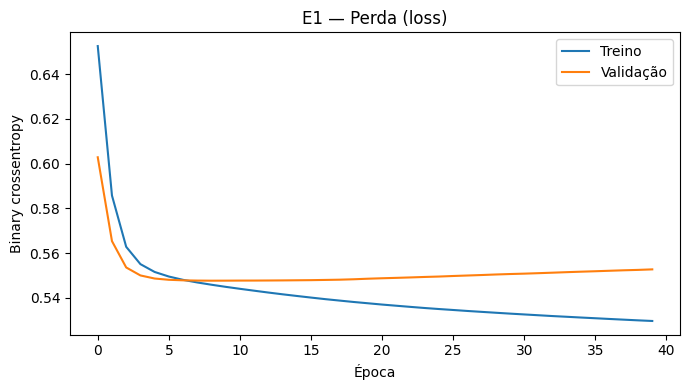

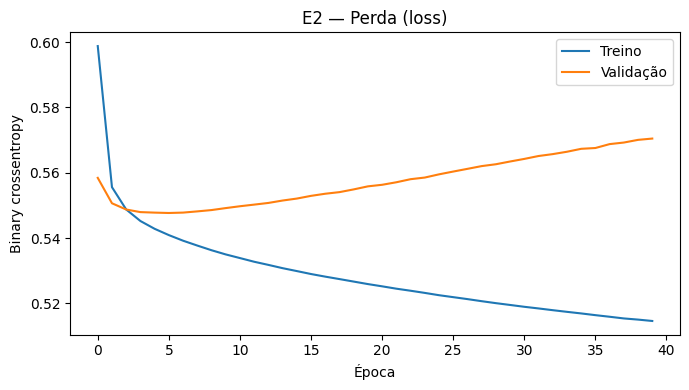

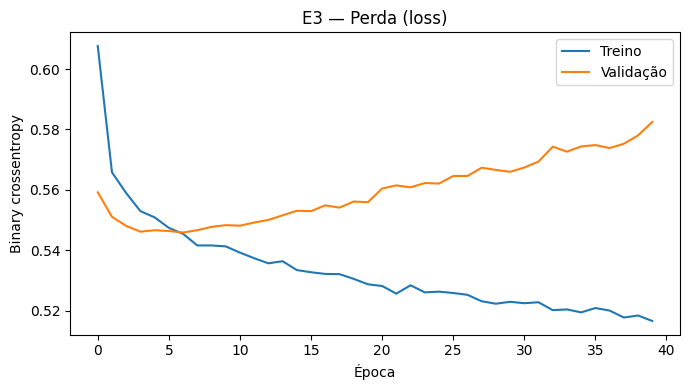

In [ ]:
for exp_id, h in historicos.items():
    plt.figure(figsize=(7, 4))
    plt.plot(h['loss'], label='Treino')
    plt.plot(h['val_loss'], label='Validação')
    plt.title(f'{exp_id} — Perda (loss)')
    plt.xlabel('Época')
    plt.ylabel('Binary crossentropy')
    plt.legend()
    plt.tight_layout()
    plt.show()

### 9.3. Curvas de acurácia: treino e validação

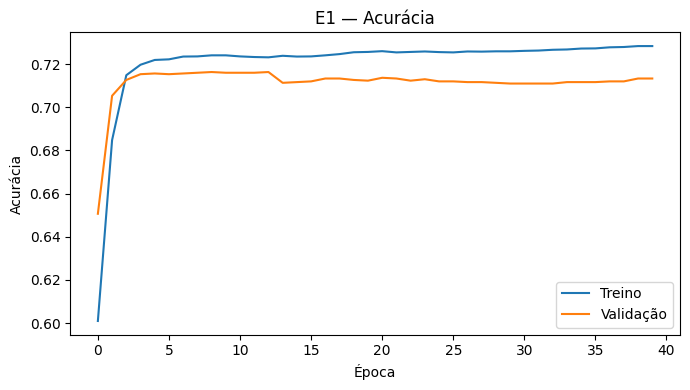

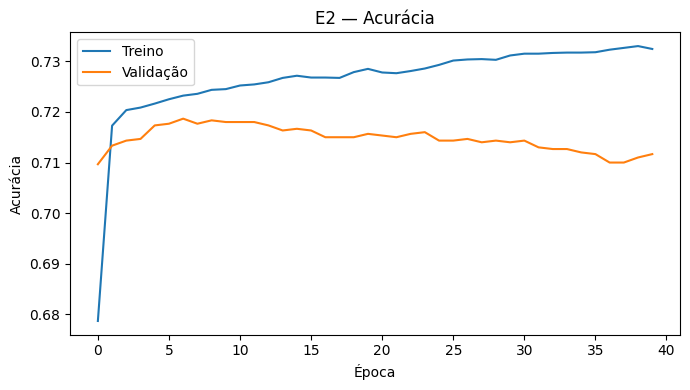

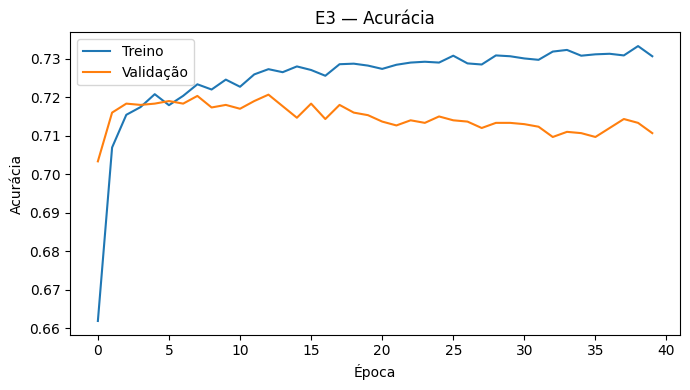

In [ ]:
for exp_id, h in historicos.items():
    plt.figure(figsize=(7, 4))
    plt.plot(h['accuracy'], label='Treino')
    plt.plot(h['val_accuracy'], label='Validação')
    plt.title(f'{exp_id} — Acurácia')
    plt.xlabel('Época')
    plt.ylabel('Acurácia')
    plt.legend()
    plt.tight_layout()
    plt.show()

### 9.4. Matriz de confusão do melhor modelo (validação)

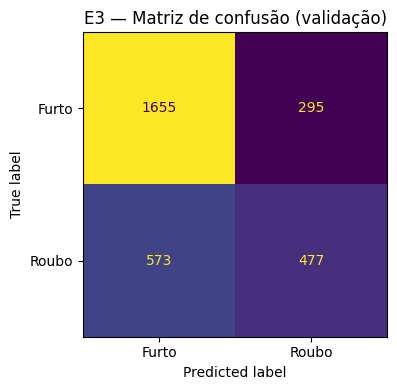

In [ ]:
cm = matrizes[melhor_id]
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(cm, display_labels=['Furto', 'Roubo'])
disp.plot(ax=ax, colorbar=False)
ax.set_title(f'{melhor_id} — Matriz de confusão (validação)')
plt.tight_layout()
plt.show()

# Inspecione as curvas: treino muito superior à validação sugere overfitting;
# ambos ruins podem indicar underfitting. Documente a análise após executar.

## 10. Avaliação final no conjunto de teste

Modelo escolhido: E3
Loss teste: 0.5745
Acurácia: 0.716
Precisão: 0.6268
Recall: 0.4643
F1-score: 0.5334
              precision    recall  f1-score   support

       Furto       0.75      0.85      0.80      1951
       Roubo       0.63      0.46      0.53      1049

    accuracy                           0.72      3000
   macro avg       0.69      0.66      0.66      3000
weighted avg       0.71      0.72      0.70      3000



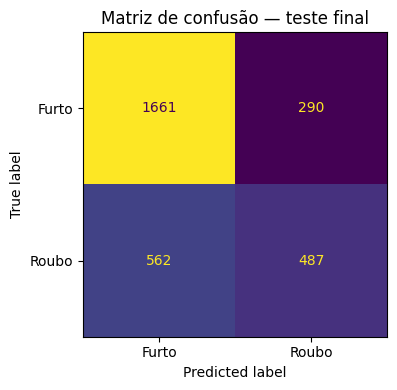

In [ ]:
# O conjunto de teste é utilizado apenas DEPOIS de escolher a arquitetura.
modelo_final = modelos[melhor_id]
y_test_a = y_test.to_numpy(dtype='float32')

loss_teste, acc_teste = modelo_final.evaluate(X_test_p, y_test_a, verbose=0)
prob_teste = modelo_final.predict(X_test_p, verbose=0).ravel()
pred_teste = (prob_teste >= LIMIAR).astype(int)

print('Modelo escolhido:', melhor_id)
print('Loss teste:', round(loss_teste, 4))
print('Acurácia:', round(accuracy_score(y_test_a, pred_teste), 4))
print('Precisão:', round(precision_score(y_test_a, pred_teste, zero_division=0), 4))
print('Recall:', round(recall_score(y_test_a, pred_teste, zero_division=0), 4))
print('F1-score:', round(f1_score(y_test_a, pred_teste, zero_division=0), 4))
print(classification_report(y_test_a, pred_teste, target_names=['Furto', 'Roubo'], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test_a, pred_teste, display_labels=['Furto', 'Roubo'], ax=ax, colorbar=False
)
ax.set_title('Matriz de confusão — teste final')
plt.tight_layout()
plt.show()

## 11. Salvar modelo e pré-processador para a aplicação web

In [ ]:
# Estes arquivos devem acompanhar o app no GitHub (ou ser reconstruíveis).
modelo_final.save('modelo_mlp.keras')
joblib.dump(preprocessador, 'preprocessador.joblib')

metadados = {
    'atributos': atributos,
    'bairros_mantidos': bairros_mantidos,
    'locais_mantidos': locais_mantidos,
    'dias_semana': ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo', 'Desconhecido'],
    'periodos': ['Madrugada', 'Manhã', 'Tarde', 'Noite', 'Desconhecido'],
    'limiar': LIMIAR,
    'modelo_escolhido': melhor_id,
    'classes': {'0': 'Furto', '1': 'Roubo'}
}
with open('metadados.json', 'w', encoding='utf-8') as f:
    json.dump(metadados, f, ensure_ascii=False, indent=2)

print('Arquivos criados: modelo_mlp.keras, preprocessador.joblib, metadados.json')

# Faça download dos três arquivos para desenvolver o Streamlit no VS Code.
from google.colab import files
for nome in ['modelo_mlp.keras', 'preprocessador.joblib', 'metadados.json']:
    files.download(nome)

Arquivos criados: modelo_mlp.keras, preprocessador.joblib, metadados.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Observações para o relatório

- **Origem dos dados:** SSP-SP, arquivo de celulares subtraídos de 2026; indicar a data em que o arquivo foi baixado e confirmar o intervalo de datas de ocorrência no recorte final.
- **Recorte:** cidade do fato = `S.PAULO`, classes `Furto (art. 155)` e `Roubo (art. 157)`.
- **Exclusões:** outras naturezas, chaves de boletim ambíguas e repetições de itens e versões dentro do mesmo BO.
- **Atributos:** bairro, dia da semana, período e tipo de local; não são usadas informações pessoais nem o próprio rótulo.
- **Limitação:** o agrupamento por BO procura evitar a repetição de um fato e vazamento entre treino e teste; o critério de identificação deve ser validado com o dicionário da fonte.
- **Interpretação:** probabilidade estimada de ser roubo *dado que ocorreu uma ocorrência com essas características*. Não representa risco de crime futuro.
- **Uso de IA generativa:** assistência na adaptação do notebook, revisão de código, documentação e testes; a equipe deve verificar os resultados calculados.